In [3]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
torch.manual_seed(42)

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [6]:
# Force CPU:
device = torch.device("cpu")
device

device(type='cpu')

In [7]:
torch.cuda.is_available()

True

In [8]:
X_test = pd.read_csv('./DATASET/team10/task1/test_data.csv')
y_test = pd.read_csv("./DATASET/team10/task1/test_label.csv")
X_train = pd.read_csv('./DATASET/team10/task1/train_data.csv')
y_train = pd.read_csv("./DATASET/team10/task1/train_label.csv")
X_val = pd.read_csv('./DATASET/team10/task1/val_data.csv')
y_val = pd.read_csv("./DATASET/team10/task1/val_label.csv")

In [9]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((1999, 36), (1999, 1), (499, 36), (499, 1), (499, 36), (499, 1))

In [10]:
len(y_train.iloc[:,0].unique())

5

In [11]:
class CustomDataset(Dataset):
  def __init__(self,features, labels):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long).squeeze(1)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, index):
    return self.features[index], self.labels[index]

In [12]:
train_dataset = CustomDataset(X_train.values, y_train.values)
test_dataset = CustomDataset(X_test.values, y_test.values)
val_dataset = CustomDataset(X_val.values, y_val.values)

In [13]:
len(train_dataset), len(test_dataset), len(val_dataset)

(1999, 499, 499)

In [15]:
# train_loader = DataLoader(train_dataset, batch_size = 1, shuffle = True, pin_memory=True)
# test_loader = DataLoader(test_dataset, batch_size = 1, shuffle = False, pin_memory=True)
# val_loader = DataLoader(val_dataset, batch_size = 1, shuffle = True, pin_memory=True)

train_loader = DataLoader(train_dataset,shuffle=True, batch_size = 1, pin_memory=True)
test_loader = DataLoader(test_dataset,shuffle=True, batch_size = 1, pin_memory=True)
val_loader = DataLoader(val_dataset, shuffle=True, batch_size = 1, pin_memory=True)

In [14]:
class MyNN(nn.Module):

  def __init__(self, num_features, num_classes):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 20),
        nn.Tanh(),
        nn.Linear(20,10),
        nn.Tanh(),
        nn.Linear(10,num_classes),
    )

  def forward(self, x):
    return self.model(x)

In [16]:
learning_rate = 0.1
threshold = 1e-3

In [17]:
def initialize_model():
  model = MyNN(X_train.shape[1], len(y_train.iloc[:,0].unique()))
  # model.to(device)
  return model

In [18]:
model = MyNN(X_train.shape[1], len(y_train.iloc[:,0].unique()))
model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer0 = optim.SGD(model.parameters(), lr = learning_rate)
# optimizer1 = optim.Adadelta(model.parameters(), lr = learning_rate)
# optimizer2 = optim.Adagrad(model.parameters(), lr = learning_rate)
# optimizer3 = optim.RMSprop(model.parameters(), lr = learning_rate)
# optimizer4 = optim.Adam(model.parameters(), lr = learning_rate)

In [26]:
torch.manual_seed(42)
model2 = MyNN(X_train.shape[1], len(y_train.iloc[:,0].unique()))

In [27]:
weights_1 = model.model[0].weight
weights_2 = model2.model[0].weight
is_equal = torch.equal(weights_1, weights_2)
print(is_equal)

True


In [28]:
epoch0 = 0
SGD_loss = -1
while(epoch0 < 100000):
  total_epoch_loss = 0
  for batch_features, batch_labels in train_loader:
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    #forward pass
    outputs = model(batch_features)

    #loss
    loss = criterion(outputs, batch_labels)

    #backprop
    optimizer0.zero_grad()
    loss.backward()
    optimizer0.step()

    total_epoch_loss += loss.item()

  avg_loss = total_epoch_loss / len(train_loader)
  print(f'Epoch: {epoch0 + 1}, Loss: {avg_loss}')
  epoch0 += 1
  if(SGD_loss == -1):
    SGD_loss = avg_loss
  elif(abs(avg_loss - SGD_loss) < 1e-3):
    SGD_loss = avg_loss
    break


Epoch: 1, Loss: 1.3952373842233088
Epoch: 2, Loss: 1.24909536520568
Epoch: 3, Loss: 1.2015461500523508
Epoch: 4, Loss: 1.1542832402665244
Epoch: 5, Loss: 1.1586114237198664
Epoch: 6, Loss: 1.133296921733709
Epoch: 7, Loss: 1.1205129919773067
Epoch: 8, Loss: 1.1048266853696447
Epoch: 9, Loss: 1.1122065326636876
Epoch: 10, Loss: 1.112069839397338
Epoch: 11, Loss: 1.1034481856056964
Epoch: 12, Loss: 1.1077238999089583
Epoch: 13, Loss: 1.067913353204608
Epoch: 14, Loss: 1.093953275225177
Epoch: 15, Loss: 1.093596144825809
Epoch: 16, Loss: 1.0944272269506012
Epoch: 17, Loss: 1.0825712700011494
Epoch: 18, Loss: 1.069185133111906
Epoch: 19, Loss: 1.0778864369778454
Epoch: 20, Loss: 1.0743550166227724
Epoch: 21, Loss: 1.0860785707540666
Epoch: 22, Loss: 1.0752039712619852
Epoch: 23, Loss: 1.0747740253810307
Epoch: 24, Loss: 1.0635565791042403
Epoch: 25, Loss: 1.0745976928145387
Epoch: 26, Loss: 1.0645435255229578
Epoch: 27, Loss: 1.055457957936409
Epoch: 28, Loss: 1.0544906598397006
Epoch: 29,

KeyboardInterrupt: 

In [29]:
learning_rates = {
    "SGD" : 0.01,
    "AdaGrad" : 0.01,
    "Adadelta" : 0.01,
    "RMSProp" : 0.01,
    "Adam" : 0.01
}

In [30]:
optimizers = {
    "SGD" : optim.SGD,
    "AdaGrad" : optim.Adagrad,
    "Adadelta" : optim.Adadelta,
    "RMSProp" : optim.RMSprop,
    "Adam" : optim.Adam
}

In [31]:
def train_model(optimizer_class, learning_rate, threshold = 1e-4, max_epochs = 1000):
  model = initialize_model().to(device)
  optimizer = optimizer_class(model.parameters(), lr = learning_rate)

  prev_loss = float('inf')

  loss_history = []

  for epoch in range(max_epochs):
    total_epoch_loss = 0
    for batch_features, batch_labels in train_loader:
      batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

      outputs = model(batch_features)

      loss = criterion(outputs, batch_labels)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      total_epoch_loss += loss.item()

    avg_loss = total_epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f'Epoch: {epoch + 1}, Loss: {avg_loss}')

    if abs(prev_loss - avg_loss) < threshold:
      print("Converged")
      break

    prev_loss = avg_loss

  return model, loss_history

In [32]:
results = {}
for optimizer_name, optimizer_class in optimizers.items():
  learning_rate = learning_rates[optimizer_name]
  print(f"----------------- Training with {optimizer_name} -----------------")
  model, loss_history = train_model(optimizer_class, learning_rate)
  print(f"----------------------------------------------------------------")
  results[optimizer_name] = {
      "model" : model,
      "loss_history" : loss_history
  }


----------------- Training with SGD -----------------
Epoch: 1, Loss: 1.597060517468054
Epoch: 2, Loss: 1.4357107544486496
Epoch: 3, Loss: 1.2757906742196432
Epoch: 4, Loss: 1.2098945651115807
Epoch: 5, Loss: 1.1737665148948568
Epoch: 6, Loss: 1.1453430284599235
Epoch: 7, Loss: 1.1264789290386081
Epoch: 8, Loss: 1.0923820083202416
Epoch: 9, Loss: 1.0544390570481363
Epoch: 10, Loss: 1.0220403913534308
Epoch: 11, Loss: 1.007102814662117
Epoch: 12, Loss: 0.9939968068350206
Epoch: 13, Loss: 0.976895712321161
Epoch: 14, Loss: 0.9715437557254305
Epoch: 15, Loss: 0.9694140924559184
Epoch: 16, Loss: 0.9650058918735064
Epoch: 17, Loss: 0.9549184153490086
Epoch: 18, Loss: 0.952254427269869
Epoch: 19, Loss: 0.9457951198933481
Epoch: 20, Loss: 0.9480643139582774
Epoch: 21, Loss: 0.9397228166182386
Epoch: 22, Loss: 0.937170497615127
Epoch: 23, Loss: 0.9340678562883991
Epoch: 24, Loss: 0.9328526823852247
Epoch: 25, Loss: 0.9294131514982038
Epoch: 26, Loss: 0.9240391477881901
Epoch: 27, Loss: 0.92078

---------------------------- Plot for SGD ----------------------------


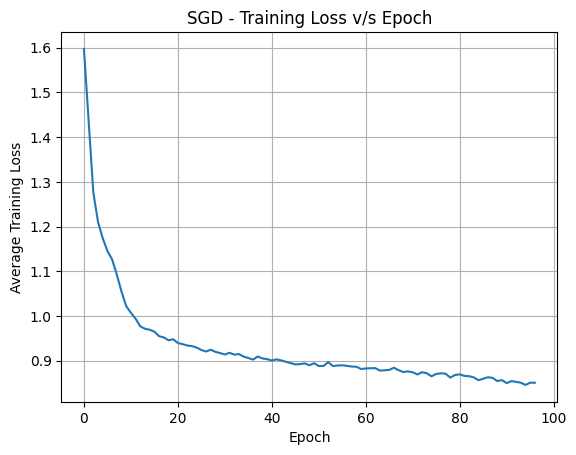

---------------------------- Plot for AdaGrad ----------------------------


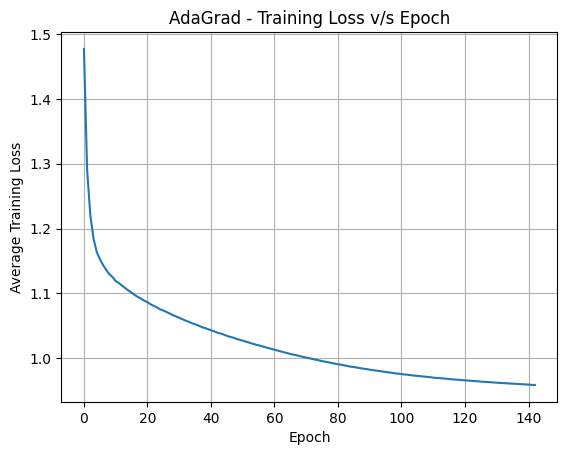

---------------------------- Plot for Adadelta ----------------------------


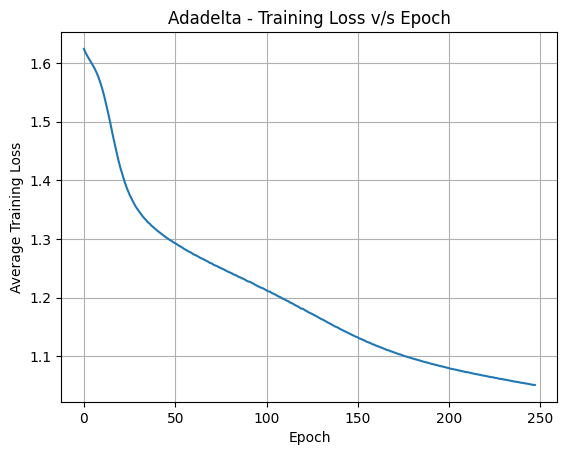

---------------------------- Plot for RMSProp ----------------------------


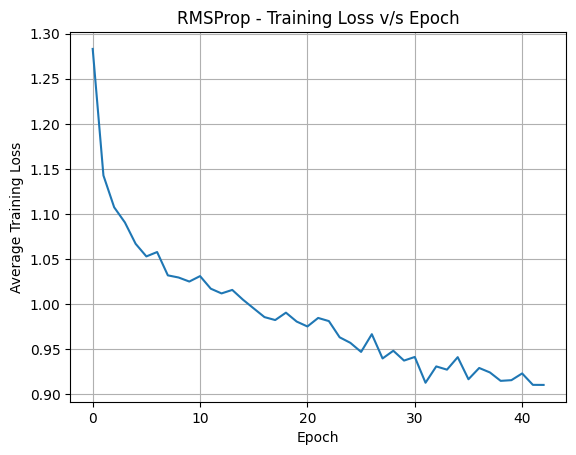

---------------------------- Plot for Adam ----------------------------


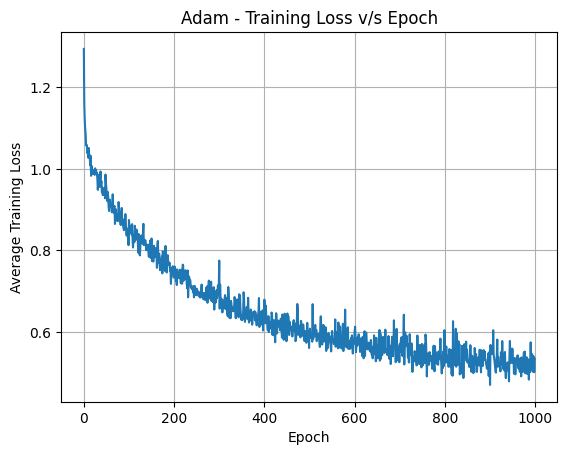

In [33]:
for optimizer_name in results:
  print(f"---------------------------- Plot for {optimizer_name} ----------------------------")
  plt.figure()
  plt.plot(results[optimizer_name]["loss_history"])
  plt.title(f"{optimizer_name} - Training Loss v/s Epoch")
  plt.xlabel("Epoch")
  plt.ylabel("Average Training Loss")
  plt.grid(True)
  plt.show()

In [34]:
def evaluate_model(model, loader):
  model.eval()

  all_preds = []
  all_labels = []

  with torch.no_grad():
    for features, labels in loader:
      features, labels = features.to(device), labels.to(device)

      output = model(features)

      _, predicted = torch.max(output, 1)

      all_preds.extend(predicted.cpu().numpy())
      all_labels.extend(labels.cpu().numpy())

  return all_labels, all_preds

-------------------------------- SGD --------------------------------


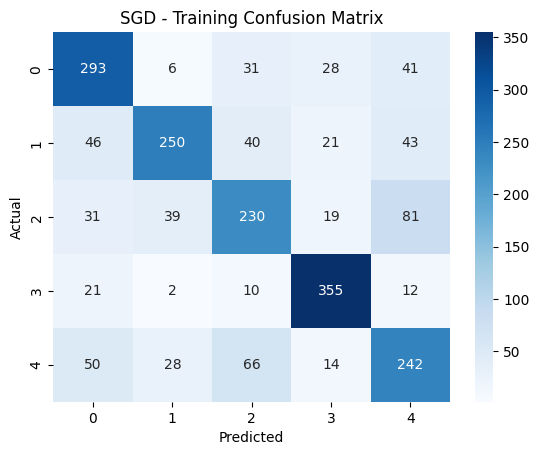

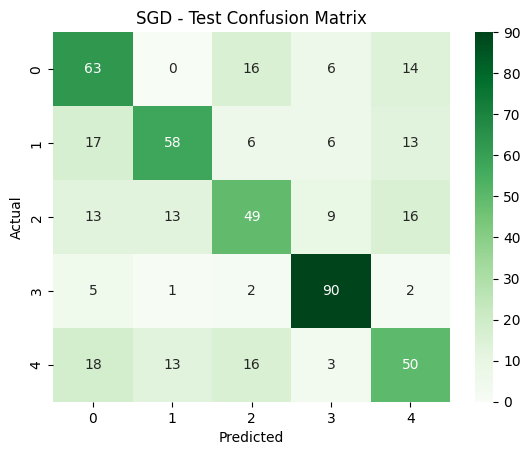

-------------------------------- AdaGrad --------------------------------


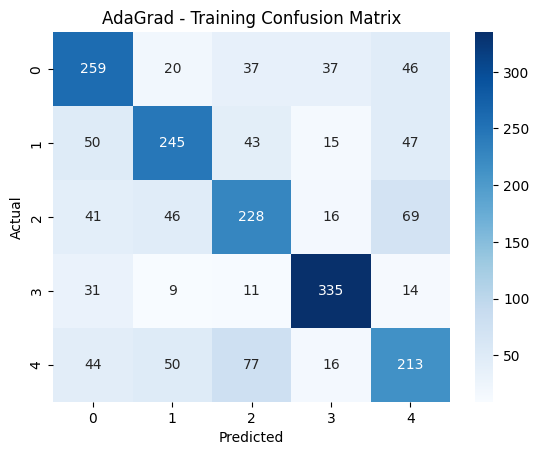

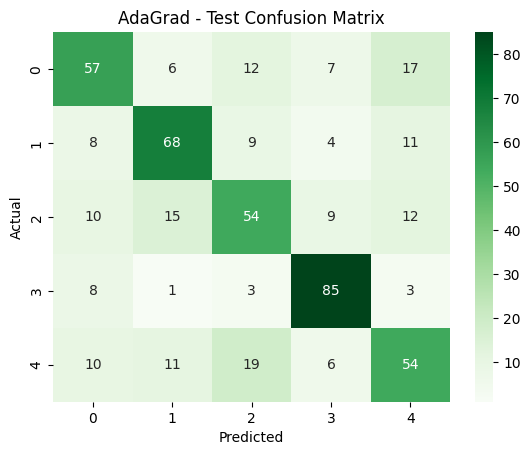

-------------------------------- Adadelta --------------------------------


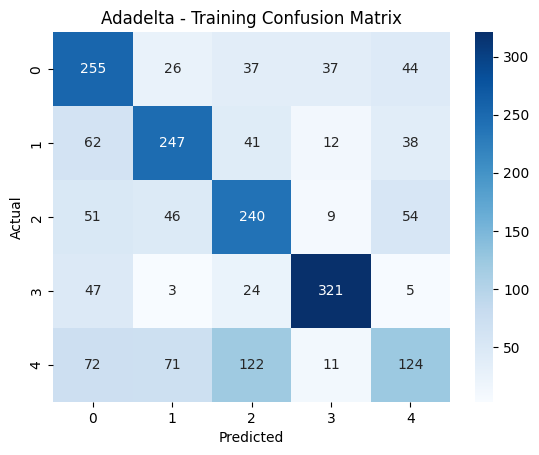

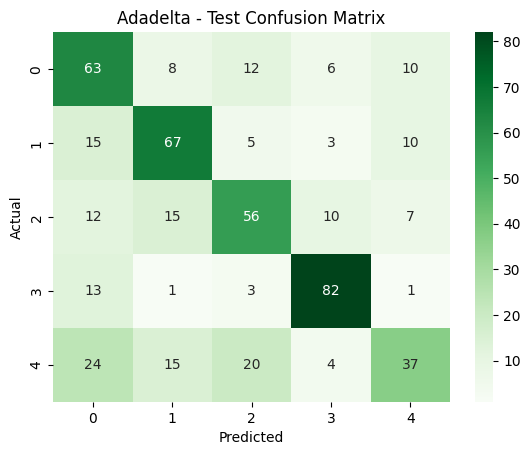

-------------------------------- RMSProp --------------------------------


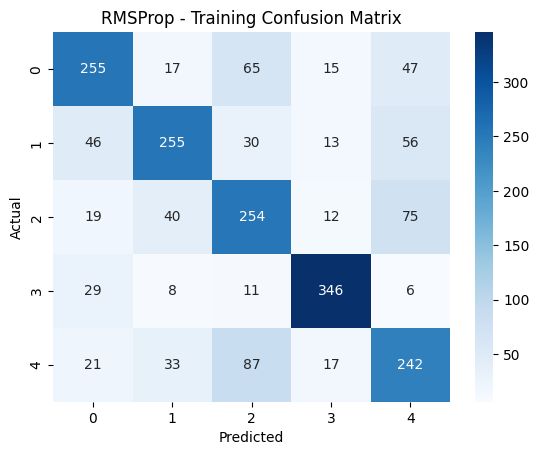

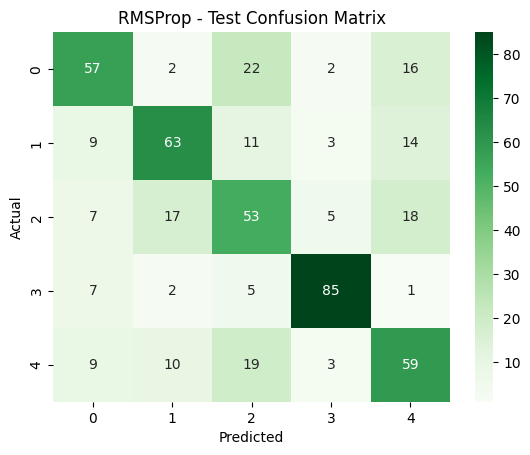

-------------------------------- Adam --------------------------------


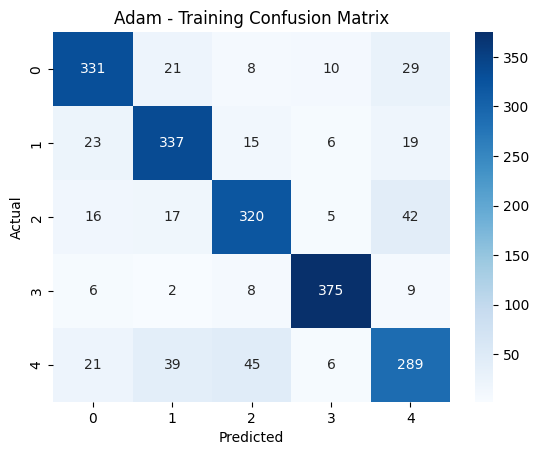

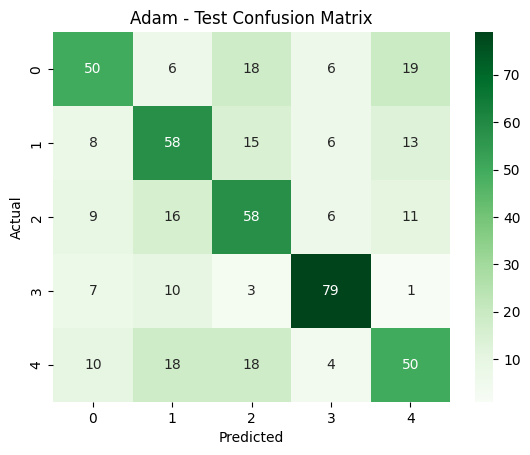

In [35]:
for optimizer_name in results:
  print(f"-------------------------------- {optimizer_name} --------------------------------")

  model = results[optimizer_name]["model"]

  #Training
  train_labels, train_preds = evaluate_model(model, train_loader)
  cm_train = confusion_matrix(train_labels, train_preds)

  plt.figure()
  sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues')
  plt.title(f"{optimizer_name} - Training Confusion Matrix")
  plt.xlabel("Predicted")
  plt.ylabel("Actual")
  plt.show()

  # TEST DATA
  test_labels, test_preds = evaluate_model(model, test_loader)
  cm_test = confusion_matrix(test_labels, test_preds)

  plt.figure()
  sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens')
  plt.title(f"{optimizer_name} - Test Confusion Matrix")
  plt.xlabel("Predicted")
  plt.ylabel("Actual")
  plt.show()

In [ ]:
from sklearn.metrics import classification_report

for optimizer_name in results:
    print(f"\n====================== {optimizer_name} ======================")

    model = results[optimizer_name]["model"]
    test_labels, test_preds = evaluate_model(model, test_loader)

    print(classification_report(test_labels, test_preds))


===== SGD =====
              precision    recall  f1-score   support

           0       0.49      0.83      0.62        99
           1       0.80      0.53      0.64       100
           2       0.62      0.45      0.52       100
           3       0.85      0.81      0.83       100
           4       0.55      0.54      0.54       100

    accuracy                           0.63       499
   macro avg       0.66      0.63      0.63       499
weighted avg       0.66      0.63      0.63       499


===== AdaGrad =====
              precision    recall  f1-score   support

           0       0.56      0.61      0.58        99
           1       0.67      0.65      0.66       100
           2       0.55      0.49      0.52       100
           3       0.78      0.81      0.79       100
           4       0.53      0.54      0.53       100

    accuracy                           0.62       499
   macro avg       0.62      0.62      0.62       499
weighted avg       0.62      0.62      

In [ ]:
# #ADAM
# model = initialize_model()
# adam_lr = 0.001
# optimizer4 = optim.Adam(model.parameters(), lr = adam_lr)
# epoch5 = 0
# ADAM_loss = -1
# while(epoch5 < 100000):
#   total_epoch_loss = 0
#   for batch_features, batch_labels in train_loader:
#     batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

#     #forward pass
#     outputs = model(batch_features)

#     #loss
#     loss = criterion(outputs, batch_labels)

#     #backprop
#     optimizer4.zero_grad()
#     loss.backward()
#     optimizer4.step()

#     total_epoch_loss += loss.item()

#   avg_loss = total_epoch_loss / len(train_loader)
#   print(f'Epoch: {epoch5 + 1}, Loss: {avg_loss}')
#   epoch5 += 1
#   if(ADAM_loss == -1):
#     ADAM_loss = avg_loss
#   elif(abs(avg_loss - ADAM_loss) < threshold):
#     ADAM_loss = avg_loss
#     break
